# Preprocesamiento de las noches para la CNN-Transformer

En este notebook se prepara la señal de las 153 noches de Sleep Cassette para la red CNN-Transformer. A diferencia del XGBoost, la red no recibe rasgos calculados a mano, sino la **señal cruda** de cada época de 30 s (3000 muestras por canal), a partir de la cual aprende sus propias representaciones.

El desarrollo se organiza de la siguiente manera:

1. **Librerías**
2. **Rutas y parámetros**
3. **Lectura de las noches:** etiquetas por época y ventana de sueño.
4. **Preprocesamiento:** filtrado y normalización de EEG, EOG y EMG.
5. **Preprocesamiento de las 153 noches**
6. **Ejemplo de una noche preprocesada**

## 1. Librerías

In [3]:
import json
import os
import shutil
import sys
import warnings
from pathlib import Path

if "google.colab" in sys.modules:  
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mne==1.12.1"], check=True)

import matplotlib.pyplot as plt
import mne
import numpy as np
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Rutas y parámetros

Definimos las rutas de los datos y las constantes de la señal: 100 Hz y épocas de 30 s.

In [4]:
# Carpeta del repositorio dentro de MyDrive (solo se usa en Colab)
CARPETA_DRIVE = "prueba_MAIA_Trabajo_de_Grado_DeepSleep_Stacking"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive") / CARPETA_DRIVE
else:
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())

DATA = RAIZ / "data"
EDF = DATA / "sleep-cassette"
if EN_COLAB:
    local = Path("/content/sleep-cassette")
    local.mkdir(exist_ok=True)
    edfs = sorted(EDF.glob("SC4*.edf"))
    assert len(edfs) == 306, f"en {EDF} hay {len(edfs)} EDF y deben ser 306: ¿terminó de subir a Drive?"
    for src in edfs:
        dst = local / src.name
        if not dst.exists() or dst.stat().st_size != src.stat().st_size:
            shutil.copy2(src, dst)
    EDF = local
NOCHES = DATA / "procesados" / "cnn_transformer" / "noches"
NOCHES.mkdir(parents=True, exist_ok=True)

particion = json.loads((RAIZ / "particiones.json").read_text())
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]
FS, EPOCH = 100, 30
SPE = FS * EPOCH   # muestras por época
CHANNELS = {"fpz": "EEG Fpz-Cz", "pz": "EEG Pz-Oz", "eog": "EOG horizontal", "emg": "EMG submental"}
print("Colab:", EN_COLAB)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab: True


## 3. Lectura de las noches

### Archivos

Cada noche `SC4ssN` (ss = sujeto, N = noche) tiene un archivo de señales (`*-PSG.edf`) y uno de anotaciones (`*-Hypnogram.edf`).

In [5]:
# Función para listar las noches con sus dos archivos
def list_nights(raw_dir):
    psgs = {p.name[:6]: p for p in Path(raw_dir).glob("SC4*-PSG.edf")}
    hyps = {p.name[:6]: p for p in Path(raw_dir).glob("SC4*-Hypnogram.edf")}
    return [(k, psgs[k], hyps[k]) for k in sorted(psgs) if k in hyps]


nights = list_nights(EDF)
print(f"{len(nights)} noches")

153 noches


### Etiquetas por época

Las anotaciones, en norma R&K, se convierten a una etiqueta por época de 30 s en norma AASM, uniendo S3 y S4 en N3. Las épocas `Sleep stage ?` y `Movement time` quedan con etiqueta −1.

In [6]:
# Función para convertir el hipnograma en una etiqueta por época
STAGE_MAP = {"Sleep stage W": 0, "Sleep stage 1": 1, "Sleep stage 2": 2,
             "Sleep stage 3": 3, "Sleep stage 4": 3, "Sleep stage R": 4}
UNKNOWN = -1


def hypnogram_labels(hyp_path, n_epochs, epoch_sec=EPOCH):
    ann = mne.read_annotations(hyp_path)
    labels = np.full(n_epochs, UNKNOWN, dtype=np.int64)
    for onset, duration, desc in zip(ann.onset, ann.duration, ann.description):
        start = int(round(onset / epoch_sec))
        stop = min(start + int(round(duration / epoch_sec)), n_epochs)
        labels[start:stop] = STAGE_MAP.get(desc, UNKNOWN)
    return labels

### Ventana de sueño

Se conserva la ventana de sueño de cada noche, desde 30 min antes del primer estadio de sueño hasta 30 min después del último, y se descartan las épocas sin etiqueta. Quedan 195 469 épocas, las mismas del XGBoost.

In [7]:
# Función para encontrar la ventana de sueño de una noche
def sleep_window(labels, wake_margin_min=30, epoch_sec=EPOCH):
    sleep_idx = np.where(labels > 0)[0]
    margin = int(wake_margin_min * 60 / epoch_sec)
    return max(sleep_idx[0] - margin, 0), min(sleep_idx[-1] + margin, len(labels) - 1)

## 4. Preprocesamiento

### EEG y EOG

Fpz-Cz, Pz-Oz y EOG (100 Hz) se filtran con un pasa-banda de 0.3 a 35 Hz (FIR, ventana de Hamming) sobre el registro completo. Luego cada época se normaliza con un z-score, de modo que queda con media 0 y desviación 1. Se almacenan en float16 para reducir memoria.

In [8]:
# Función para el z-score de cada época
def zscore(x):
    return ((x - x.mean(1, keepdims=True)) / (x.std(1, keepdims=True) + 1e-8)).astype(np.float32)

### EMG

El EMG viene como envolvente a 1 Hz (30 valores por época). Se transforma con log(1 + µV) y se normaliza con un z-score robusto por noche (mediana e IQR), ya que su escala varía mucho entre personas.

La función `load_night` aplica todo el preprocesamiento a una noche.

In [9]:
# Función para leer y preprocesar una noche
def load_night(psg_path, hyp_path):
    """fpz, pz, eog: (n, 3000) float16 · emg: (n, 30) · y: (n,) · pos: posición de cada época en el registro."""
    raw = mne.io.read_raw_edf(psg_path, include=list(CHANNELS.values()), preload=True, verbose="error")
    data = {k: raw.get_data(picks=[ch])[0] for k, ch in CHANNELS.items()}
    n = len(data["fpz"]) // SPE
    labels = hypnogram_labels(hyp_path, n, EPOCH)
    first, last = sleep_window(labels, 30, EPOCH)
    keep = np.arange(first, last + 1)
    keep = keep[labels[keep] != UNKNOWN]

    out = {"y": labels[keep].astype(np.int64), "pos": keep}
    for k in ("fpz", "pz", "eog"):
        sig = mne.filter.filter_data(data[k], FS, 0.3, 35.0, method="fir", fir_window="hamming", verbose="error")
        out[k] = zscore(sig[: n * SPE].reshape(n, SPE)[keep]).astype(np.float16)
    # El EMG viene a 1 Hz y MNE lo interpola a 100 Hz: cada 100 muestras está el valor original
    emg = np.log1p(np.abs(data["emg"][: n * SPE: FS].reshape(n, EPOCH)[keep]) * 1e6)
    med = np.median(emg)
    iqr = np.subtract(*np.percentile(emg, [75, 25])) or 1.0
    out["emg"] = ((emg - med) / iqr).astype(np.float32)
    return out

### Una época antes y después

Comparamos una época de N2 de Fpz-Cz en su forma original y después del filtrado y la normalización.

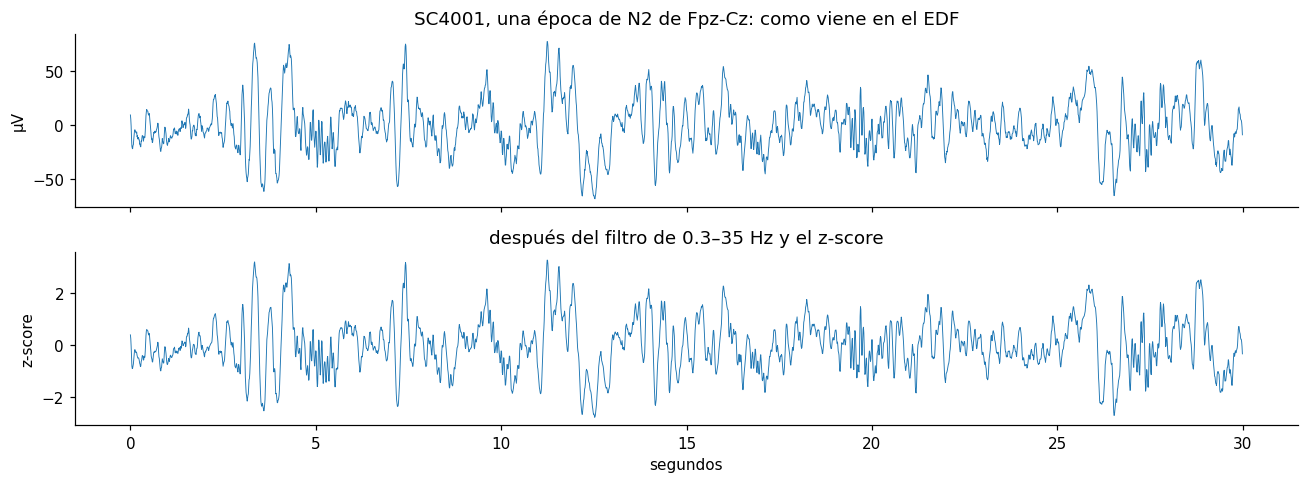

In [10]:
# Una época de N2 de la primera noche, antes y después del preprocesamiento
nid, psg, hyp = nights[0]
raw = mne.io.read_raw_edf(psg, include=[CHANNELS["fpz"]], preload=True, verbose="error")
cruda = raw.get_data()[0]
etiquetas = hypnogram_labels(hyp, len(cruda) // SPE)
e = int(np.where(etiquetas == 2)[0][100])
filtrada = mne.filter.filter_data(cruda, FS, 0.3, 35.0, method="fir", fir_window="hamming", verbose="error")
t = np.arange(SPE) / FS

fig, axes = plt.subplots(2, 1, figsize=(12, 4.5), sharex=True)
axes[0].plot(t, cruda[e * SPE:(e + 1) * SPE] * 1e6, lw=0.6)
axes[0].set_ylabel("µV")
axes[0].set_title(f"{nid}, una época de N2 de Fpz-Cz: como viene en el EDF")
axes[1].plot(t, zscore(filtrada[e * SPE:(e + 1) * SPE][None])[0], lw=0.6)
axes[1].set_ylabel("z-score")
axes[1].set_title("después del filtro de 0.3–35 Hz y el z-score")
axes[1].set_xlabel("segundos")
plt.tight_layout()
plt.show()

## 5. Preprocesamiento de las 153 noches

Cada noche se guarda en un archivo `.npz`. Al final verificamos que el número de épocas por estadio coincida con el de `particiones.json`.

In [11]:
# Preprocesamiento de las 153 noches
def preprocess(job):
    nid, psg, hyp = job
    np.savez(NOCHES / f"{nid}.npz", **load_night(psg, hyp))


pendientes = [n for n in nights if not (NOCHES / f"{n[0]}.npz").exists()]
Parallel(n_jobs=os.cpu_count())(delayed(preprocess)(j) for j in pendientes)

conteo = np.zeros(5, dtype=int)
for nid, _, _ in nights:
    conteo += np.bincount(np.load(NOCHES / f"{nid}.npz")["y"], minlength=5)
esperado = particion["resumen"]["todos"]["epocas_por_estadio"]
print(f"{len(nights)} noches, {conteo.sum():,} épocas:", dict(zip(ESTADIOS, conteo.tolist())))
assert conteo.tolist() == [esperado[s] for s in ESTADIOS], "las épocas no coinciden con las del proyecto"

153 noches, 195,469 épocas: {'W': 65941, 'N1': 21522, 'N2': 69132, 'N3': 13039, 'REM': 25835}


## 6. Ejemplo de una noche preprocesada

Una época de N2 en los 4 canales: tres señales de 3000 muestras y el EMG con 30 valores.

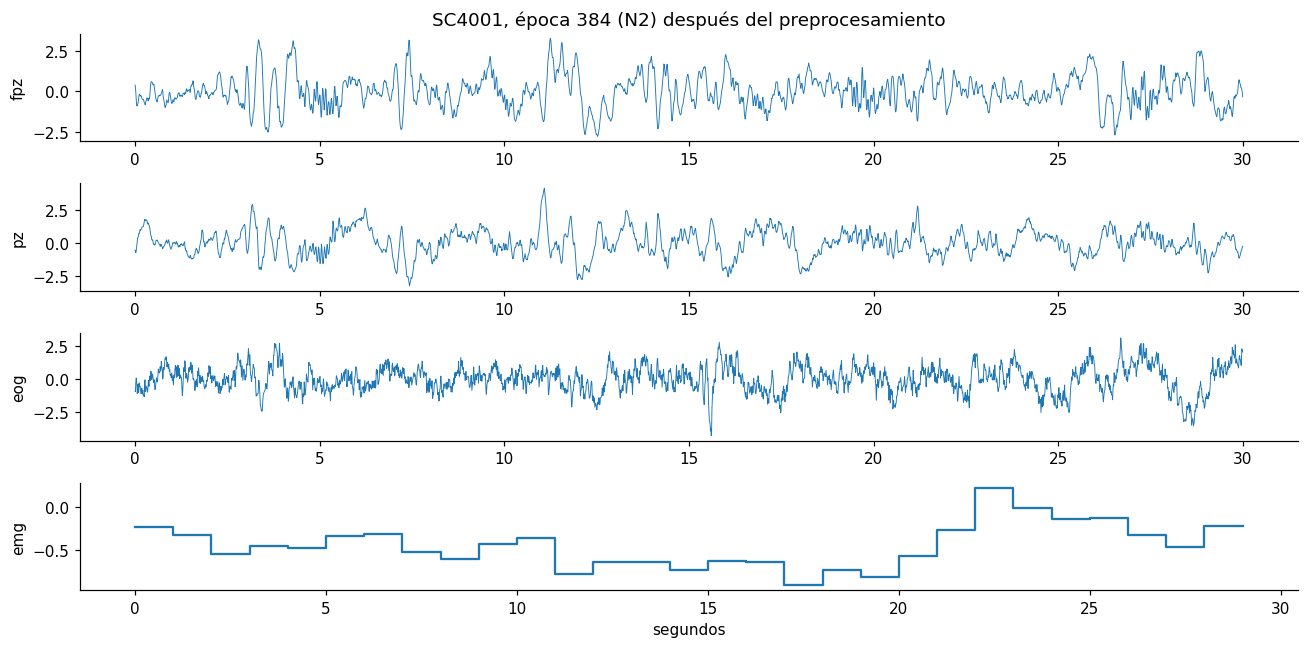

In [12]:
# Una época de N2 de la primera noche, en los 4 canales
ejemplo = np.load(NOCHES / f"{nights[0][0]}.npz")
e = int(np.where(ejemplo["y"] == 2)[0][100])   # una época de N2
fig, axes = plt.subplots(4, 1, figsize=(12, 6), sharex=False)
for ax, k in zip(axes[:3], ("fpz", "pz", "eog")):
    ax.plot(np.arange(SPE) / FS, ejemplo[k][e].astype(float), lw=0.6)
    ax.set_ylabel(k)
axes[3].step(np.arange(EPOCH), ejemplo["emg"][e], where="post")
axes[3].set_ylabel("emg")
axes[3].set_xlabel("segundos")
axes[0].set_title(f"{nights[0][0]}, época {e} (N2) después del preprocesamiento")
plt.tight_layout()
plt.show()